In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory
from scipy import stats
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
import src
from src import (
    CELL_LINE_COLOUR,
    DIAGONAL,
    arm_colour,
    ORIGIN,
    PATHWAY_COLOUR,
    axis_ticks,
    save_plot,
    ticked_axis,
    square_axes,
)

STUDY = C.THIS_STUDY

## Data


In [2]:
library = pd.read_csv(C.dataset_file(STUDY, "library"))
zscores = pd.read_csv(C.dataset_file(STUDY, "zscores"), index_col=0)
lognorm = pd.read_csv(C.dataset_file(STUDY, "lognorm"), index_col=0)
hits = pd.read_csv(C.dataset_file(STUDY, "hits"))

In [3]:
library

,guide,study,guide_type,control_type,gene,n_genes,ensembl_gene,transcript,transcript_version,chromosome,...,n_variants_cbe,mutation_category_cbe,n_variants_abe,mutation_category_abe,ot_0mm,ot_1mm,ot_2mm,ot_3mm,ot_4mm,ot_overflow
0,AAAACATCACCATTGTGACA,BECancerResistome,targeting,NaN,ITGA3,1,ENSG00000005884,ENST00000320031,13,17.0,...,2.0,Silent,NaN,NaN,1.0,0.0,7.0,98.0,1014.0,False
1,AAAAGCCAAGTCTGAGACTG,BECancerResistome,targeting,NaN,ITGA3,1,ENSG00000005884,ENST00000320031,13,17.0,...,2.0,Missense,NaN,NaN,1.0,0.0,14.0,220.0,2434.0,False
2,AAAATAGGCGCCCACCTGCG,BECancerResistome,targeting,NaN,ITGA3,1,ENSG00000005884,ENST00000320031,13,17.0,...,0.0,No edits,NaN,NaN,1.0,0.0,0.0,5.0,145.0,False
3,AAACCAAAGGCAGAGCCACT,BECancerResistome,targeting,NaN,ITGA3,1,ENSG00000005884,ENST00000320031,13,17.0,...,2.0,Missense,NaN,NaN,1.0,0.0,6.0,85.0,915.0,False
4,AAACTGTGGAGGATGTAGGA,BECancerResistome,targeting,NaN,ITGA3,1,ENSG00000005884,ENST00000320031,13,17.0,...,1.0,Missense,NaN,NaN,1.0,0.0,8.0,118.0,1089.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39451,CGACGCTAACGCGTCGGAAT,BECancerResistome,non_targeting,negative,NaN,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,5.0,False
39452,TCCCGCAAAACGATCGATCC,BECancerResistome,non_targeting,negative,NaN,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,36.0,False
39453,TGGTAGTACTACGACGATAG,BECancerResistome,non_targeting,negative,NaN,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,46.0,False
39454,ACCCGTATCCTTTCGACGCG,BECancerResistome,non_targeting,negative,NaN,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,16.0,False


In [4]:
library["control_type"].value_counts()

control_type
negative    1000
positive      72
Name: count, dtype: int64

In [6]:
guide_type = library.set_index("guide").guide_type
gene = library.set_index("guide").gene

print(f"{len(zscores):,} sgRNAs past the plasmid filter")
print(f"{zscores.shape[1]} replicate comparisons, {hits.condition.nunique()} conditions")
print(guide_type.reindex(zscores.index).value_counts().to_dict())

38,982 sgRNAs past the plasmid filter
28 replicate comparisons, 14 conditions
{'targeting': 37920, 'non_targeting': 991, 'splice_essential': 71}


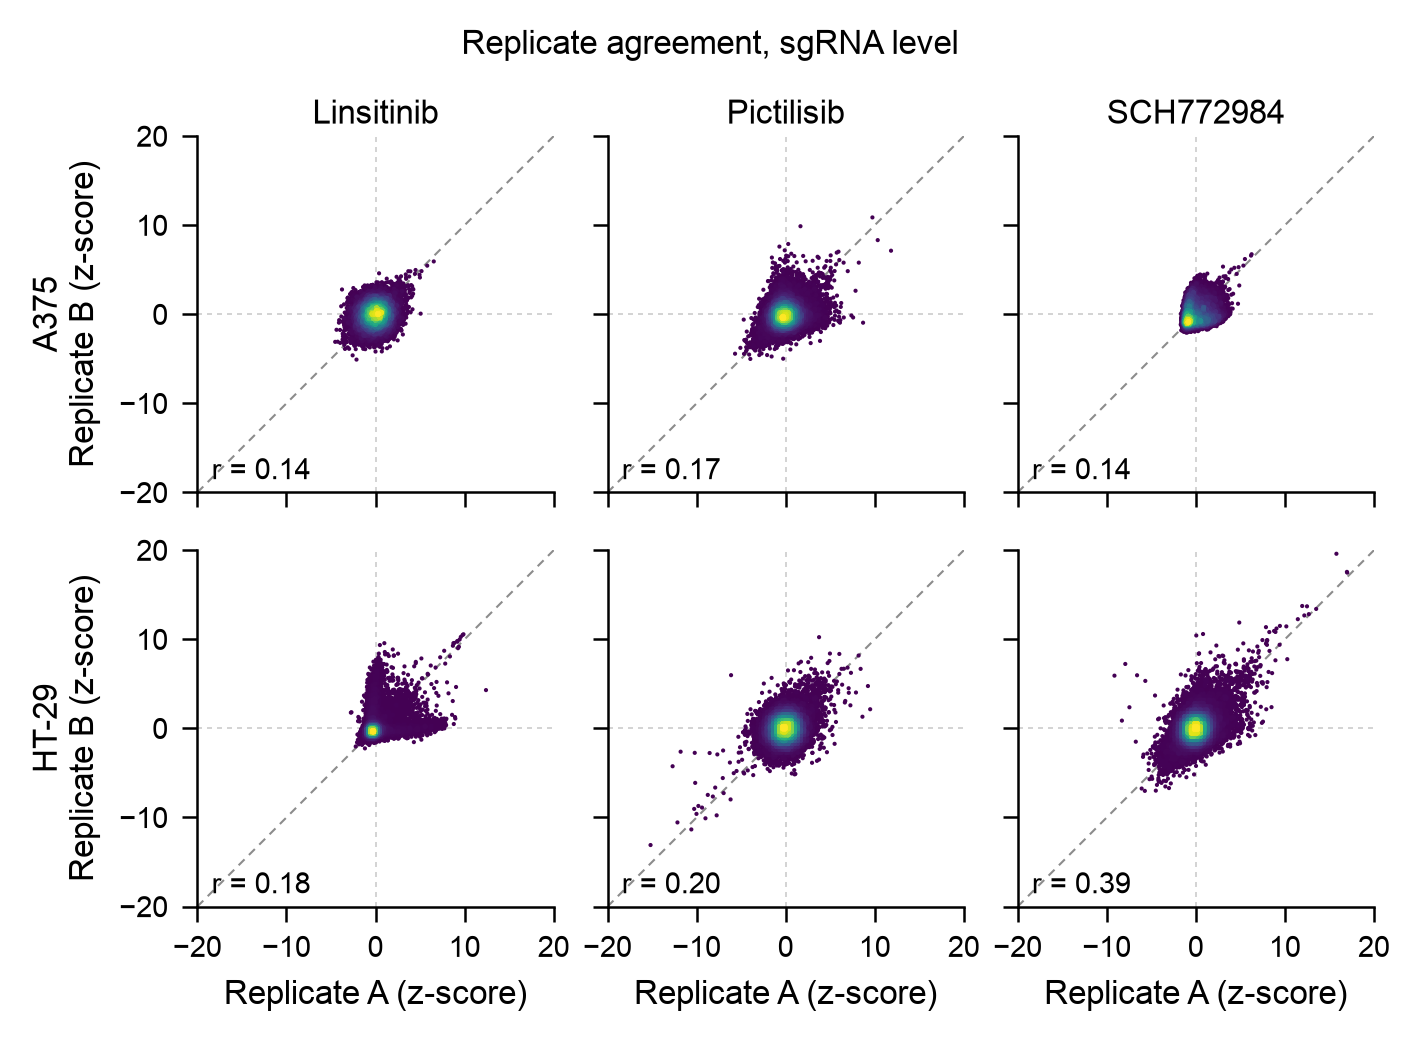

In [7]:
def density_scatter(ax, x, y, bins=70, size=1.0):
    """Scatter coloured by local point density, densest points drawn last."""
    counts, xedges, yedges = np.histogram2d(x, y, bins=bins)
    ix = np.clip(np.digitize(x, xedges[1:-1]), 0, bins - 1)
    iy = np.clip(np.digitize(y, yedges[1:-1]), 0, bins - 1)
    density = counts[ix, iy]
    order = density.argsort()
    return ax.scatter(
        x[order],
        y[order],
        c=density[order],
        cmap="viridis",
        s=size,
        linewidths=0,
        rasterized=True,
    )


drug_pairs = {
    (cell_line, arm): (f"{cell_line}_{arm}_RepA_vs_DO", f"{cell_line}_{arm}_RepB_vs_DO")
    for cell_line in C.CELL_LINES
    for arm in C.DRUG_ARMS
}

spread = np.concatenate(
    [zscores[list(pair)].to_numpy().ravel() for pair in drug_pairs.values()]
)
reach = np.nanmax(np.abs(spread))
TICKS = axis_ticks(-reach, reach)

fig, axes = plt.subplots(2, 3, figsize=(4.6, 3.3), sharex=True, sharey=True)

for row, cell_line in enumerate(C.CELL_LINES):
    for column, arm in enumerate(C.DRUG_ARMS):
        ax = axes[row, column]
        rep_a, rep_b = drug_pairs[(cell_line, arm)]
        pair = zscores[[rep_a, rep_b]].dropna()
        x, y = pair[rep_a].to_numpy(), pair[rep_b].to_numpy()

        density_scatter(ax, x, y)
        ax.plot([TICKS[0], TICKS[-1]], [TICKS[0], TICKS[-1]], **DIAGONAL)
        ax.axhline(0, **ORIGIN)
        ax.axvline(0, **ORIGIN)
        ax.set_xticks(TICKS)
        ax.set_yticks(TICKS)
        ax.set_xlim(TICKS[0], TICKS[-1])
        ax.set_ylim(TICKS[0], TICKS[-1])
        ax.set_aspect("equal")

        r = stats.pearsonr(x, y)[0]
        ax.annotate(
            f"r = {r:.2f}",
            xy=(0.04, 0.02),
            xycoords="axes fraction",
            ha="left",
            va="bottom",
            fontsize=7,
        )
        if row == 0:
            ax.set_title(C.ARM_LABEL[arm], fontsize=8, pad=3)
        if column == 0:
            ax.set_ylabel(f"{C.CELL_LINE_LABEL[cell_line]}\nReplicate B (z-score)")
        if row == len(C.CELL_LINES) - 1:
            ax.set_xlabel("Replicate A (z-score)")

fig.suptitle("Replicate agreement, sgRNA level", fontsize=8, y=1.01)
fig.tight_layout(pad=0.3, w_pad=0.4, h_pad=0.4)
save_plot(fig, "qc_replicate_drug_vs_untreated")
plt.show()

## Replicate agreement, untreated versus plasmid


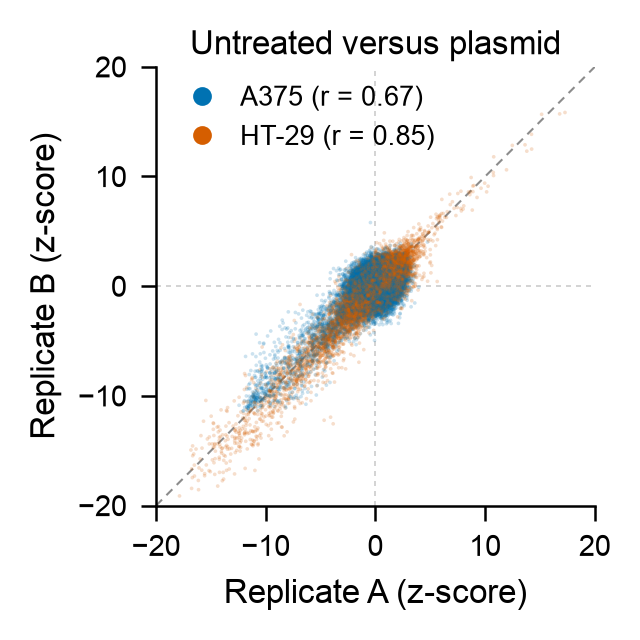

In [8]:
fig, ax = plt.subplots(figsize=(2, 2))

points, colours, correlation = [], [], {}
for cell_line in C.CELL_LINES:
    rep_a = f"{cell_line}_DO_RepA_vs_pDNA"
    rep_b = f"{cell_line}_DO_RepB_vs_pDNA"
    pair = zscores[[rep_a, rep_b]].dropna()
    points.append(pair.to_numpy())
    colours += [CELL_LINE_COLOUR[cell_line]] * len(pair)
    correlation[cell_line] = stats.pearsonr(pair[rep_a], pair[rep_b])[0]

points = np.vstack(points)
colours = np.array(colours)
shuffled = np.random.default_rng(0).permutation(len(points))
ax.scatter(
    points[shuffled, 0],
    points[shuffled, 1],
    s=0.8,
    linewidths=0,
    alpha=0.2,
    c=colours[shuffled],
    rasterized=True,
)

handles = [
    Line2D(
        [], [], marker="o", ls="", markersize=3.5,
        color=CELL_LINE_COLOUR[cell_line],
        label=f"{C.CELL_LINE_LABEL[cell_line]} (r = {correlation[cell_line]:.2f})",
    )
    for cell_line in C.CELL_LINES
]
ax.legend(
    handles=handles,
    loc="upper left",
    frameon=False,
    fontsize=6.5,
    handletextpad=0.4,
    borderaxespad=0.3,
)

ticks = square_axes(ax, points)
ax.plot([ticks[0], ticks[-1]], [ticks[0], ticks[-1]], **DIAGONAL)
ax.axhline(0, **ORIGIN)
ax.axvline(0, **ORIGIN)
ax.set_xlabel("Replicate A (z-score)")
ax.set_ylabel("Replicate B (z-score)")
ax.set_title("Untreated versus plasmid", fontsize=8, pad=3)
fig.tight_layout(pad=0.3)
save_plot(fig, "qc_replicate_untreated_vs_plasmid")
plt.show()

## Separation of essential from non-targeting guides


In [9]:
def dropout_score(cell_line):
    """Mean untreated versus plasmid z-score over replicates, flipped for depletion."""
    columns = [f"{cell_line}_DO_Rep{rep}_vs_pDNA" for rep in ("A", "B")]
    return -zscores[columns].mean(axis=1)


classes = guide_type.reindex(zscores.index)
scored = classes.isin(["splice_essential", "non_targeting"])
truth = (classes[scored] == "splice_essential").astype(int)

print(f"{int(truth.sum())} essential splice-site guides, {int((~truth.astype(bool)).sum())} non-targeting")

71 essential splice-site guides, 991 non-targeting


In [10]:
for cell_line in C.CELL_LINES:
    score = dropout_score(cell_line)[scored]
    aupr = average_precision_score(truth, score)
    auroc = roc_auc_score(truth, score)
    print(f"{C.CELL_LINE_LABEL[cell_line]}: AUPR = {aupr:.3f}, AUROC = {auroc:.3f}")

A375: AUPR = 0.391, AUROC = 0.681
HT-29: AUPR = 0.424, AUROC = 0.680


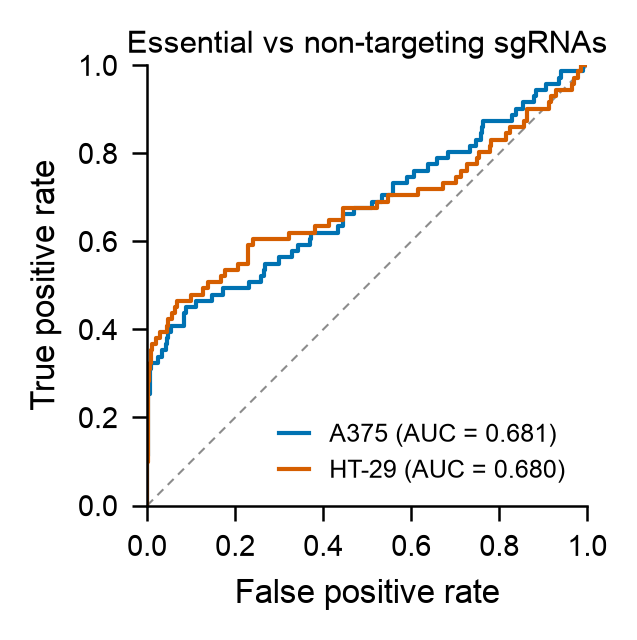

In [11]:
fig, ax = plt.subplots(figsize=(2, 2))
for cell_line in C.CELL_LINES:
    score = dropout_score(cell_line)[scored]
    fpr, tpr, _ = roc_curve(truth, score)
    ax.plot(
        fpr, tpr, lw=1.0, color=CELL_LINE_COLOUR[cell_line],
        label=f"{C.CELL_LINE_LABEL[cell_line]} (AUC = {roc_auc_score(truth, score):.3f})",
    )

ax.plot([0, 1], [0, 1], **DIAGONAL)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Essential vs non-targeting sgRNAs", fontsize=7.5, pad=3)
ticked_axis(ax, "x", 0, 1)
ticked_axis(ax, "y", 0, 1)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=6, handlelength=1.2)
fig.tight_layout(pad=0.3)
save_plot(fig, "qc_roc_essential_vs_nontargeting")
plt.show()

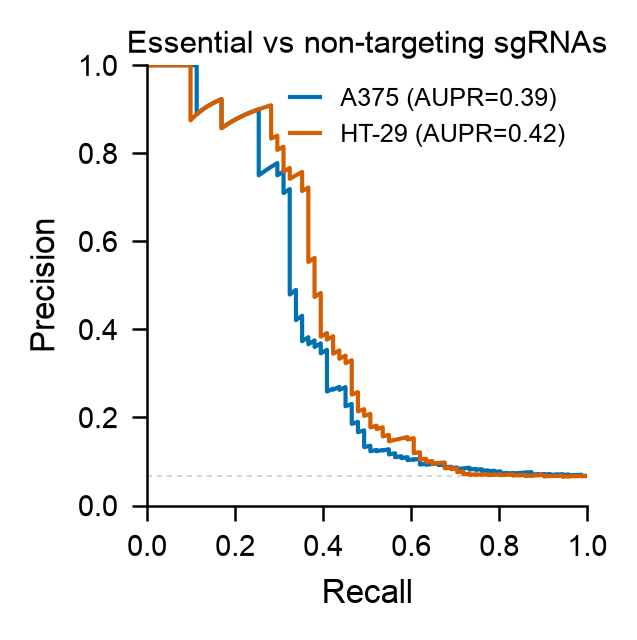

In [12]:
fig, ax = plt.subplots(figsize=(2, 2))
for cell_line in C.CELL_LINES:
    score = dropout_score(cell_line)[scored]
    precision, recall, _ = precision_recall_curve(truth, score)

    ax.plot(
        recall, precision, lw=1.0, color=CELL_LINE_COLOUR[cell_line],
        label=f"{C.CELL_LINE_LABEL[cell_line]} (AUPR={average_precision_score(truth, score):.2f})",
    )

ax.axhline(truth.mean(), **ORIGIN)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Essential vs non-targeting sgRNAs", fontsize=7.5, pad=3)
ticked_axis(ax, "x", 0, 1)
ticked_axis(ax, "y", 0, 1)
ax.set_aspect("equal")
ax.legend(loc="upper right", frameon=False, fontsize=6, handlelength=1.2)
fig.tight_layout(pad=0.3)
save_plot(fig, "qc_pr_essential_vs_nontargeting")
plt.show()

## Fold-change by guide class


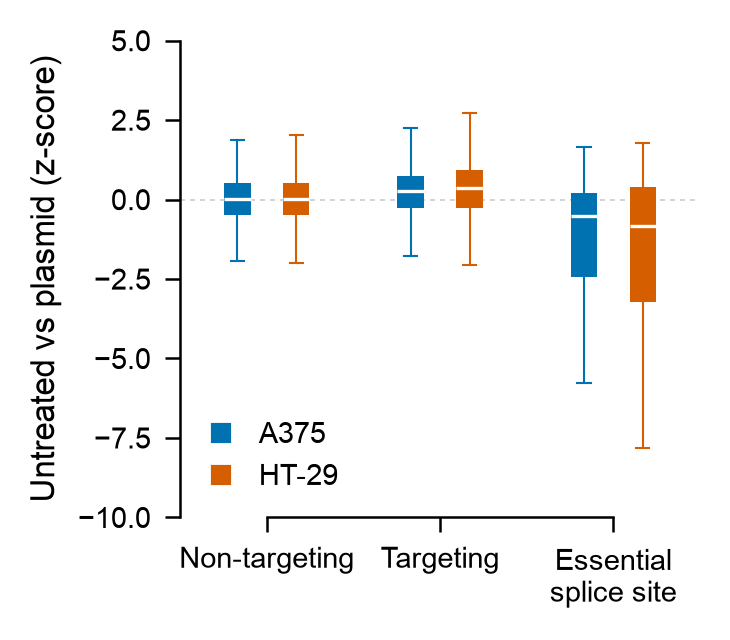

In [13]:
order = ["non_targeting", "targeting", "splice_essential"]
fig, ax = plt.subplots(figsize=(2.3, 2.0))

width = 0.34
for offset, cell_line in enumerate(C.CELL_LINES):
    score = -dropout_score(cell_line)  # back to the signed z-score, negative means depleted
    data = [score[classes == name].dropna().to_numpy() for name in order]
    positions = np.arange(len(order)) + (offset - 0.5) * width
    colour = CELL_LINE_COLOUR[cell_line]
    box = ax.boxplot(
        data,
        positions=positions,
        widths=width * 0.45,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color="white", lw=0.8),
        whiskerprops=dict(lw=0.5, color=colour),
        capprops=dict(lw=0.5, color=colour),
        boxprops=dict(lw=0.0, facecolor=colour),
    )

ax.axhline(0, **ORIGIN)
ticked_axis(ax, "y", *ax.get_ylim())
ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels([C.GUIDE_CLASS_LABEL[name] for name in order], fontsize=7)
ax.set_ylabel("Untreated vs plasmid (z-score)")
ax.set_xlim(-0.5, len(order) - 0.5)

handles = [
    Line2D([], [], marker="s", ls="", markersize=4, color=CELL_LINE_COLOUR[line],
           label=C.CELL_LINE_LABEL[line])
    for line in C.CELL_LINES
]
ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=7, handlelength=1)

fig.tight_layout(pad=0.3)
save_plot(fig, "qc_zscore_by_guide_class")
plt.show()

## Hits per gene


In [14]:
def hits_per_gene(call):
    """sgRNA hit counts of one direction, as genes by condition."""
    chosen = hits[(hits.call == call) & hits.condition.str.endswith("_vs_untreated")]
    counted = chosen.assign(gene=chosen.guide.map(gene))
    table = counted.groupby(["gene", "condition"]).size().unstack(fill_value=0)
    columns = [
        f"{cell_line}_{arm}_vs_untreated"
        for arm in C.DRUG_ARMS
        for cell_line in C.CELL_LINES
    ]
    return table.reindex(columns=columns, fill_value=0)


GENE_ORDER = [g for genes in C.GENE_GROUPS.values() for g in genes]
GENE_COLOUR = {gene: PATHWAY_COLOUR[C.GENE_PATHWAY[gene]] for gene in GENE_ORDER}
AREA_PER_HIT = 0.30
SIZE_KEYS = [1, 10, 50, 100, 200, 300]
BLOCK_GAP = 2.4  # between drugs
LINE_GAP = 1.0  # between the two cell lines of one drug


def row_position(block, within):
    return block * BLOCK_GAP + within * LINE_GAP


def dot_plot(call, title, filename):
    """Genes across, conditions down, dot area the number of sgRNAs called."""
    table = hits_per_gene(call).reindex(GENE_ORDER, fill_value=0)
    fig, ax = plt.subplots(figsize=(6.3, 2.1))
    columns_to_axes = blended_transform_factory(ax.transData, ax.transAxes)
    genes = np.arange(len(GENE_ORDER))

    rows = [(arm, line) for arm in C.DRUG_ARMS for line in C.CELL_LINES]
    for index, (arm, cell_line) in enumerate(rows):
        block, within = divmod(index, len(C.CELL_LINES))
        counts = table[f"{cell_line}_{arm}_vs_untreated"].to_numpy()
        drawn = counts > 0
        ax.scatter(
            genes[drawn],
            np.full(drawn.sum(), row_position(block, within)),
            s=counts[drawn] * AREA_PER_HIT,
            c=[GENE_COLOUR[GENE_ORDER[gene]] for gene in genes[drawn]],
            linewidths=0.15,
            edgecolors="0.3",
        )

    for gene in genes:
        ax.axvline(gene, lw=0.25, color="0.93", zorder=0)

    start = 0
    for position, (group, members) in enumerate(C.GENE_GROUPS.items()):
        if position:
            ax.axvline(start - 0.5, lw=0.5, color="0.4")
        ax.text(
            start + (len(members) - 1) / 2,
            1.03,
            group.replace("\n", " "),
            transform=columns_to_axes,
            ha="center",
            va="bottom",
            fontsize=6.5,
            fontweight="bold",
            color=PATHWAY_COLOUR[group],
        )
        start += len(members)

    positions = [
        row_position(block, within)
        for block in range(len(C.DRUG_ARMS))
        for within in range(len(C.CELL_LINES))
    ]
    ax.set_yticks(positions)
    ax.set_yticklabels([C.CELL_LINE_LABEL[line] for _, line in rows], fontsize=6)
    for block, arm in enumerate(C.DRUG_ARMS):
        ax.annotate(
            C.ARM_LABEL[arm],
            xy=(-0.075, row_position(block, 0.5)),
            xycoords=("axes fraction", "data"),
            ha="right",
            va="center",
            fontsize=7.5,
        )

    ax.set_xticks(genes)
    ax.set_xticklabels(GENE_ORDER, fontsize=6, rotation=90)
    ax.set_xlim(-0.8, len(GENE_ORDER) - 0.2)
    ax.set_ylim(positions[-1] + 0.9, positions[0] - 0.9)
    ax.set_title(title, fontsize=8, pad=14)
    ax.tick_params(axis="both", length=0)

    handles = [
        Line2D([], [], marker="o", ls="", markerfacecolor="0.6", markeredgecolor="0.3",
               markeredgewidth=0.15, markersize=np.sqrt(n * AREA_PER_HIT), label=str(n))
        for n in SIZE_KEYS
    ]
    ax.legend(
        handles=handles,
        title="sgRNAs",
        loc="upper left",
        bbox_to_anchor=(1.01, 1.05),
        frameon=False,
        fontsize=6,
        title_fontsize=6,
        labelspacing=0.9,
        borderpad=0.3,
    )

    fig.tight_layout(pad=0.3)
    save_plot(fig, filename)
    plt.show()
    return table

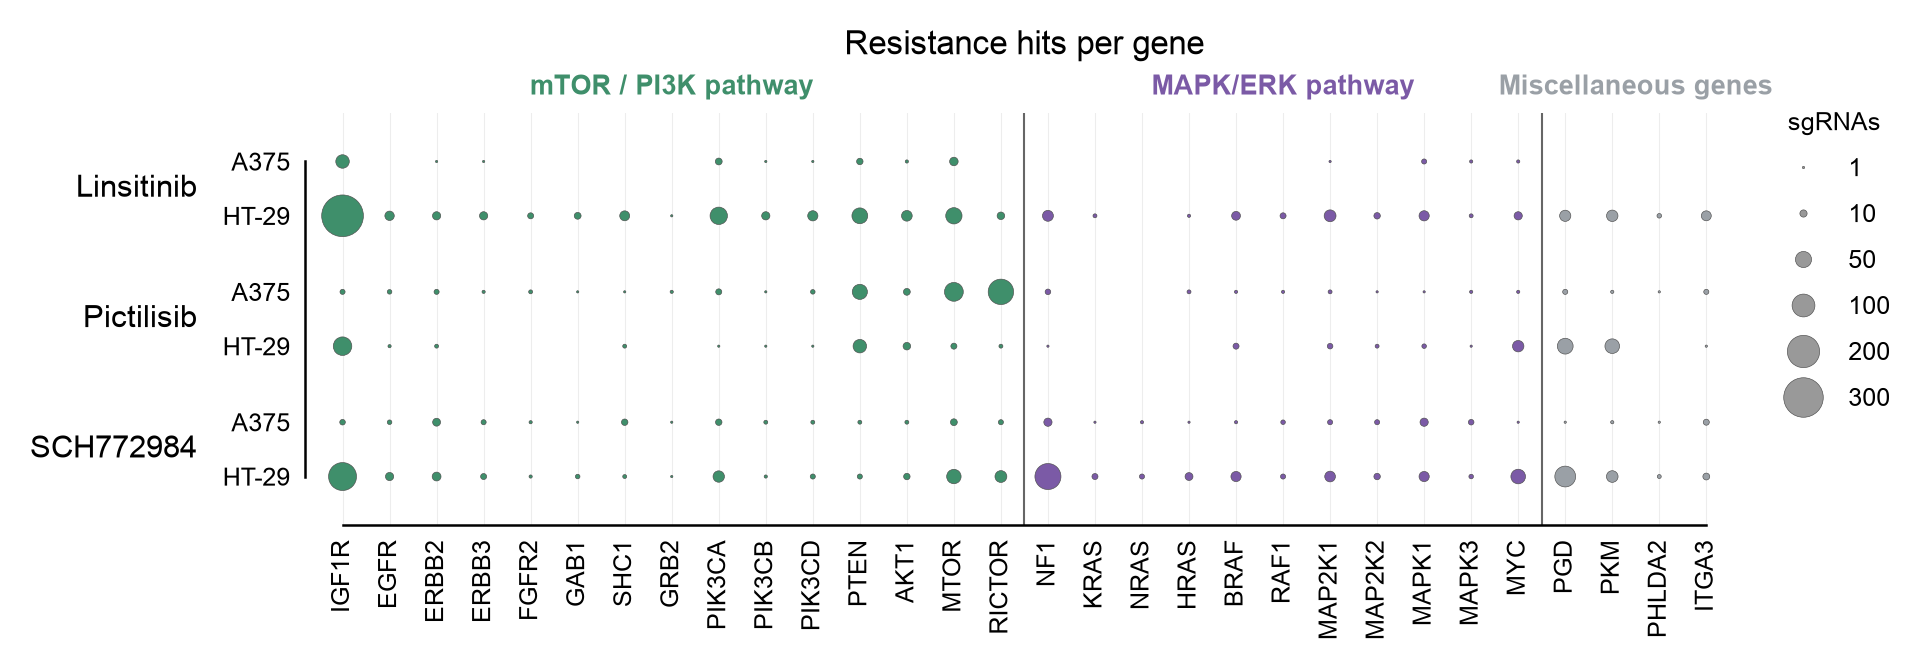

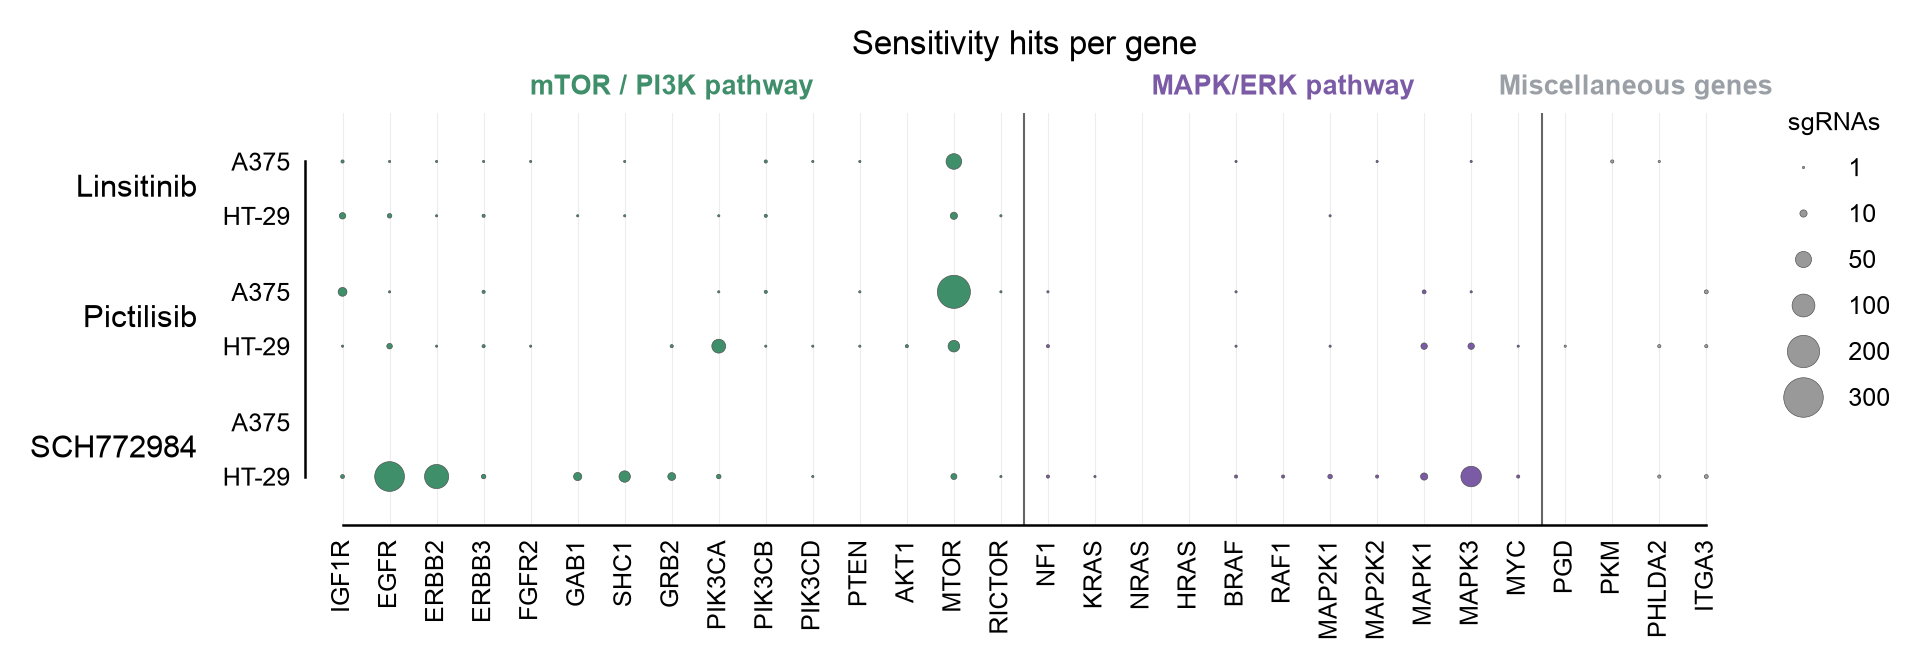

,resistance,sensitivity
condition,,
A375_LIN_vs_untreated,82,64
HT29_LIN_vs_untreated,829,32
A375_PIC_vs_untreated,315,242
HT29_PIC_vs_untreated,270,107
A375_SCH_vs_untreated,137,0
HT29_SCH_vs_untreated,702,463


In [15]:
resistance = dot_plot("resistance", "Resistance hits per gene", "hits_dotplot_resistance")
sensitivity = dot_plot("sensitivity", "Sensitivity hits per gene", "hits_dotplot_sensitivity")
pd.DataFrame({"resistance": resistance.sum(), "sensitivity": sensitivity.sum()})

## Hit counts per condition


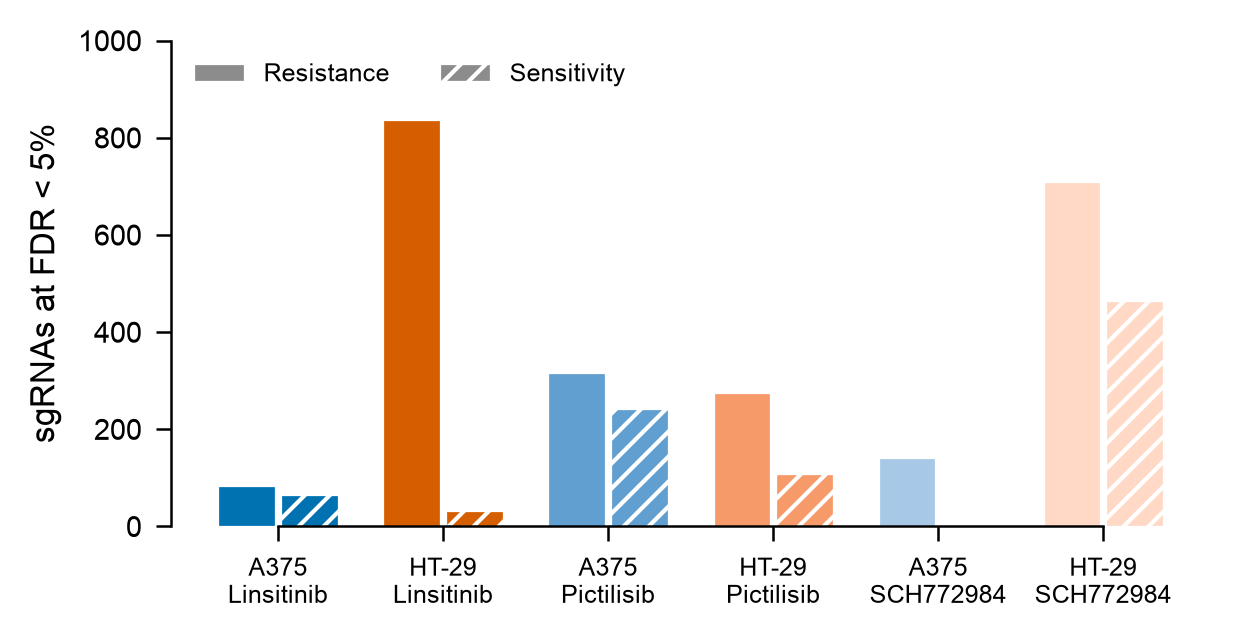

call,neutral,resistance,sensitivity
condition,,,
A375_LIN_vs_untreated,38834,84,64
HT29_LIN_vs_untreated,38113,837,32
A375_PIC_vs_untreated,38425,315,242
HT29_PIC_vs_untreated,38599,275,108
A375_SCH_vs_untreated,38841,141,0
HT29_SCH_vs_untreated,37808,709,465


In [16]:
summary = (
    hits[hits.condition.str.endswith("_vs_untreated")]
    .groupby(["condition", "call"])
    .size()
    .unstack(fill_value=0)
)
conditions = [
    f"{cell_line}_{arm}_vs_untreated"
    for arm in C.DRUG_ARMS
    for cell_line in C.CELL_LINES
]
summary = summary.reindex(conditions)

fig, ax = plt.subplots(figsize=(4.0, 2.0))
positions = np.arange(len(conditions))
width = 0.38

for offset, (call, hatch) in enumerate([("resistance", None), ("sensitivity", "////")]):
    colours = [
        arm_colour(condition.split("_")[0], condition.split("_")[1])
        for condition in conditions
    ]
    ax.bar(
        positions + (offset - 0.5) * width,
        summary[call].to_numpy(),
        width=width * 0.9,
        color=colours,
        hatch=hatch,
        edgecolor="white",
        linewidth=0.3,
        label=call.capitalize(),
    )

ax.set_xticks(positions)
ax.set_xticklabels(
    [
        f"{C.CELL_LINE_LABEL[c.split('_')[0]]}\n{C.ARM_LABEL[c.split('_')[1]]}"
        for c in conditions
    ],
    fontsize=6,
)
ax.set_ylabel("sgRNAs at FDR < 5%")
drawn_calls = ["resistance", "sensitivity"]  # the neutral column is not drawn
ticked_axis(ax, "y", 0, summary[drawn_calls].to_numpy().max() * 1.08)
handles = [
    Patch(facecolor="0.55", edgecolor="white", lw=0.3, label="Resistance"),
    Patch(facecolor="0.55", edgecolor="white", lw=0.3, hatch="////", label="Sensitivity"),
]
ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=6, ncols=2)

fig.tight_layout(pad=0.3)
save_plot(fig, "hits_per_condition")
plt.show()
summary